# Analyzing ClinVar variants

In [1]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import concurrent.futures

aa_single_to_three = {
    'A': 'Ala',  # Alanine
    'R': 'Arg',  # Arginine
    'N': 'Asn',  # Asparagine
    'D': 'Asp',  # Aspartic acid
    'C': 'Cys',  # Cysteine
    'Q': 'Gln',  # Glutamine
    'E': 'Glu',  # Glutamic acid
    'G': 'Gly',  # Glycine
    'H': 'His',  # Histidine
    'I': 'Ile',  # Isoleucine
    'L': 'Leu',  # Leucine
    'K': 'Lys',  # Lysine
    'M': 'Met',  # Methionine
    'F': 'Phe',  # Phenylalanine
    'P': 'Pro',  # Proline
    'S': 'Ser',  # Serine
    'T': 'Thr',  # Threonine
    'W': 'Trp',  # Tryptophan
    'Y': 'Tyr',  # Tyrosine
    'V': 'Val'   # Valine
}

## Loading the dbnsfp snps

In [16]:
df_clinvar_dup = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")
df_clinvar_dup.collect()

#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,SIFT_score,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean
str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
"""21""",10541137,"""G""","""C""","""V""","""L""","""rs150733676""",""".""",""".""",""".""",""".""","""13;13;13;13""","""TPTE;TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180-3;P…","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.37G>C;c.37G>C;c.37G>C;c.37G>…","""p.Val13Leu;p.Val13Leu;p.Val13L…","""c.37G>C;c.37G>C;c.37G>C;c.37G>…","""p.Val13Leu;p.Val13Leu;p.Val13L…","""alternative2;.;alternative2;pr…","""Y;.;Y;Y""","""1;5;1;1""",""".;.;.;YES""",""".;.;.;Select""","""+;+;+;+""","""GTC;GTC;GTC;GTC""","""1;1;1;1""","""0;0;0;0""","""g""","""./.""","""./.""","""./.""","""./.""",""".;.;.;.""",…,"""-""","""RCV004175219""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",10541137,10541137,"""21p11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9978559""",2,2333487,10541137,"""G""","""C""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003666233""","""-""","""-""","""37G>C ""","""Val13Leu""","""NC_000021.9:10541137:G:C""","""NM_199261.4""",1,"""4_VUS"""
"""21""",10552695,"""C""","""G""","""A""","""G""","""rs766186396""",""".""",""".""",""".""",""".""","""53;53;71""","""TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180""","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.158C>G;c.158C>G;c.212C>G""","""p.Ala53Gly;p.Ala53Gly;p.Ala71G…","""c.158C>G;c.158C>G;c.212C>G""","""p.Ala53Gly;p.Ala53Gly;p.Ala71G…","""alternative2;.;principal4""","""Y;.;Y""","""1;5;1""",""".;.;YES""",""".;.;Select""","""+;+;+""","""GCT;GCT;GCT""","""2;2;2""","""0;0;0""","""c""","""./.""","""./.""","""./.""","""./.""",""".;.;.""",…,"""-""","""RCV004203619""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",10552695,10552695,"""21p11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9978341""",2,2361661,10552695,"""C""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003696803""","""-""","""-""","""212C>G ""","""Ala71Gly""","""NC_000021.9:10552695:C:G""","""NM_199261.4""",1,"""4_VUS"""
"""21""",10561044,"""T""","""C""","""F""","""S""","""rs757957068""",""".""",""".""",""".""",""".""","""82;82;62;100""","""TPTE;TPTE;TPTE;TPTE""","""ENSG00000274391;ENSG0000027439…","""ENST00000622113;ENST0000061295…","""ENSP00000482040;ENSP0000048406…","""P56180-2;A0A087X1C4;P56180-3;P…","""TPTE_HUMAN;A0A087X1C4_HUMAN;TP…","""c.245T>C;c.245T>C;c.185T>C;c.2…","""p.Phe82S

In [8]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")
df_clinvar.collect()
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004201236""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004345528""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004275341""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""

In [3]:
# Once you’re happy with the behavior on the subset,
# you can apply it to the entire lazy DataFrame.
# Assume ldf is your lazy DataFrame.
# Randomly sample 1000 rows from the exploded DataFrame
# df_clinvar_sampled = df_clinvar_exploded.collect().sample(n=1000)

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

## AI-predictor scores distribution

In [7]:
df_clinvar_sampled_plots = df_clinvar.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

df_clinvar_sampled_plots

ESM1b_score,AlphaMissense_score,PROVEAN_score,clinvar_clnsig_clean,esm1b,alphamissense,provean
str,str,str,cat,f64,f64,f64
"""-5.093""","""0.12""","""-0.28""","""2_Benign""",-5.093,0.12,-0.28
""".""",""".""",""".""","""2_Benign""",null,null,null
"""-6.57""","""0.059""","""0.67""","""2_Benign""",-6.57,0.059,0.67
"""-1.991""","""0.0597""","""0.98""","""2_Benign""",-1.991,0.0597,0.98
"""-3.62""","""0.0714""","""-0.25""","""2_Benign""",-3.62,0.0714,-0.25
…,…,…,…,…,…,…
"""-9.584""","""0.1812""","""-3.61""","""3_Conflicting""",-9.584,0.1812,-3.61
"""-5.134""",""".""",""".""","""2_Benign""",-5.134,null,null
"""-5.814""","""0.6774""","""-1.93""","""1_Pathogenic""",-5.814,0.6774,-1.93


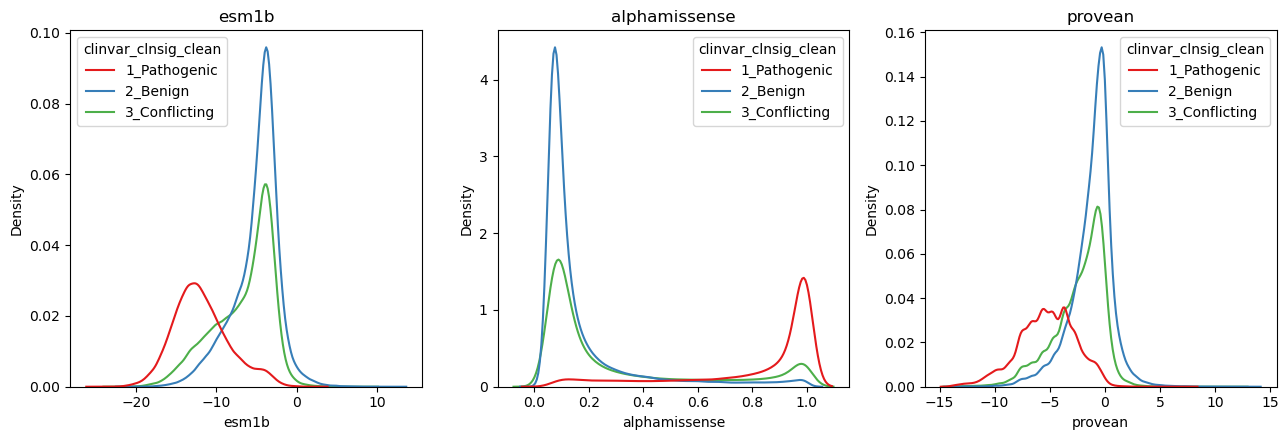

In [ ]:
# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax,
        palette="Set1"
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

## AI-predictor scores across structure

In [17]:
df_clinvar_scores = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")
df_clinvar_scores = df_clinvar_scores.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)
df_clinvar_scores.collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS""",NaN,NaN,NaN,NaN
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS""",NaN,NaN,NaN,NaN
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""","""-""","""-""","""1279G>A ""","""Val427Met""","""NC_000021.9:13630977:G:A""","""NM_174981.6""",1,"""2_Benign""",NaN,NaN,NaN,NaN
"""2277922""","""21""",13631057,"""A""","""C""","""R""","""S""",""".""",

In [6]:
df_clinvar_scores.filter(~pl.col("plddt_f32").is_nan()).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32
"""3152159""","""21""",14226962,"""C""","""A""","""S""","""Y""","""rs200152091""","""21""","""15599283""","""21""","""14521154""","""172""","""RBM11""","""ENSG00000185272""","""ENST00000400577""","""ENSP00000383421""","""P57052""","""RBM11_HUMAN""","""c.515C>A""","""p.Ser172Tyr""","""c.515C>A""","""p.Ser172Tyr""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""TCC""","""2""","""0""","""C""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",14226962,14226962,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9980000""",2,3152159,14226962,"""C""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004938037""","""-""","""-""","""515C>A ""","""Ser172Tyr""","""NC_000021.9:14226962:C:A""","""NM_144770.5""",1,"""4_VUS""",41.22,0.861538,41.220001,0.861538
"""2538423""","""21""",14373691,"""C""","""T""","""G""","""R""","""rs1982882163""","""21""","""15746012""","""21""","""14667883""","""448""","""HSPA13""","""ENSG00000155304""","""ENST00000285667""","""ENSP00000285667""","""P48723""","""HSP13_HUMAN""","""c.1342G>A""","""p.Gly448Arg""","""c.1342G>A""","""p.Gly448Arg""","""principal1""","""Y""","""1""","""YES""","""Select""","""-""","""GGA""","""1""","""0""","""C""","""C/C""","""C/C""","""C/C""","""C/C""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",14373691,14373691,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409863814""",2,2538423,14373691,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003967489""","""-""","""-""","""1342G>A ""","""Gly448Arg""","""NC_000021.9:14373691:C:T""","""NM_006948.5""",1,"""4_VUS""",82.75,0.833333,82.75,0.833333
"""2312596""","""21""",18245261,"""T""","""A""","""L""","""Q""","""rs1243713452""","""21""","""19617578""","""21""","""18539449""","""13""","""CHODL""","""ENSG00000154645""","""ENST00000299295""","""ENSP00000299295""","""Q9H9P2""","""CHODL_HUMAN""","""c.38T>A""","""p.Leu13Gln""","""c.38T>A""","""p.Leu13Gln""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""CTG""","""2""","""0""","""T""","""T/T""","""T/T""","""T/T""","""T/T""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",18245261,18245261,"""21q21.1""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409844758""",2,2312596,18245261,"""T""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003648930""","""-""","""-""","""38T>A ""","""Leu13Gln""","""NC_000021.9:18245261:T:A""","""NM_024944.3""",1,"""4_VUS""",35.63,1.0,35.630001,1.0
"""2597778""","""21""",18275273,"""T"

In [11]:
df_clinvar_w_scores = df_clinvar_scores.filter(
    ~pl.col("plddt_f32").is_nan()
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("<=90"))
        .otherwise(pl.lit("10-90"))
    ).alias("rsa_cat"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("plddt_cat"),
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
        .then(pl.lit("2_Benign"))
        .when(pl.col("AlphaMissense_pred").str.contains("P"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("A"))
        .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AM_pred"),
    (
        pl.when(pl.col("PROVEAN_pred").str.contains("D"))
        .then(pl.lit("1_Damaging"))
        .when(pl.col("PROVEAN_pred").str.contains("N"))
        .then(pl.lit("2_Neutral"))
        .otherwise(pl.lit("."))
    ).alias("Provean_pred"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("D"))
        .then(pl.lit("1_Deleterious"))
        .when(pl.col("ESM1b_pred").str.contains("T"))
        .then(pl.lit("2_Tolerated"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_pred")
)

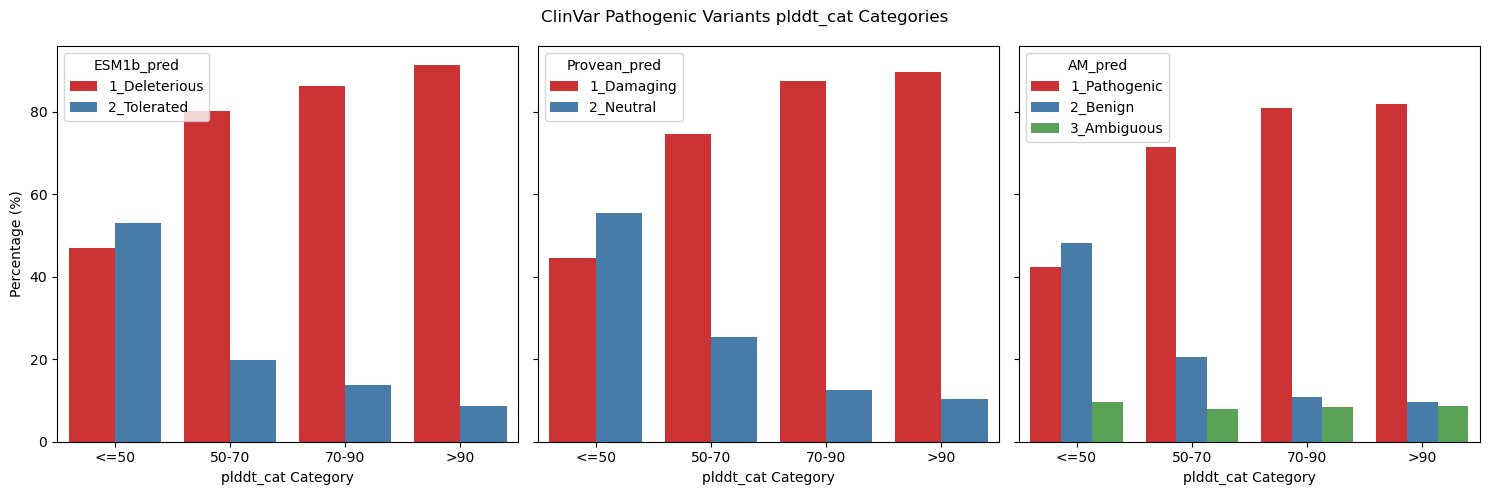

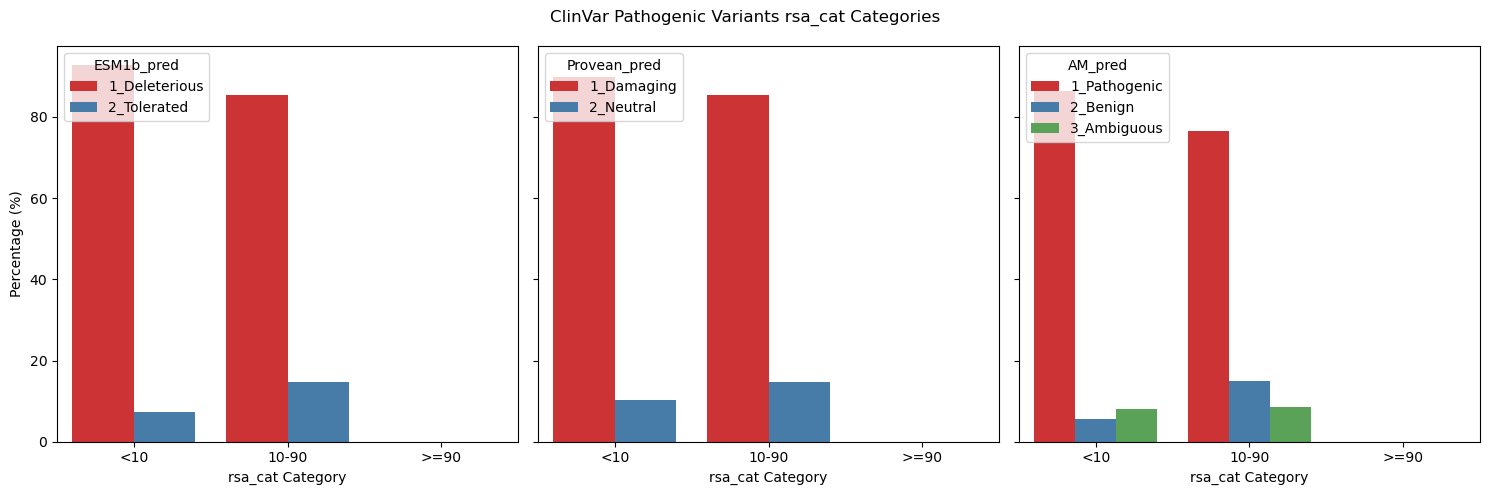

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", ">=90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Pathogenic Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

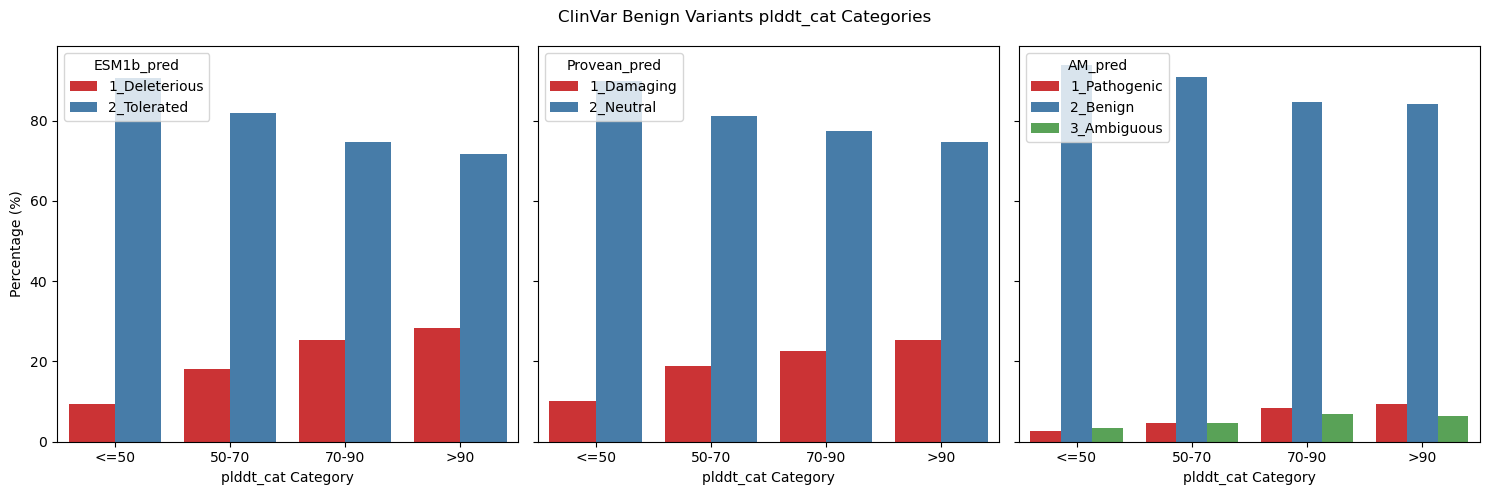

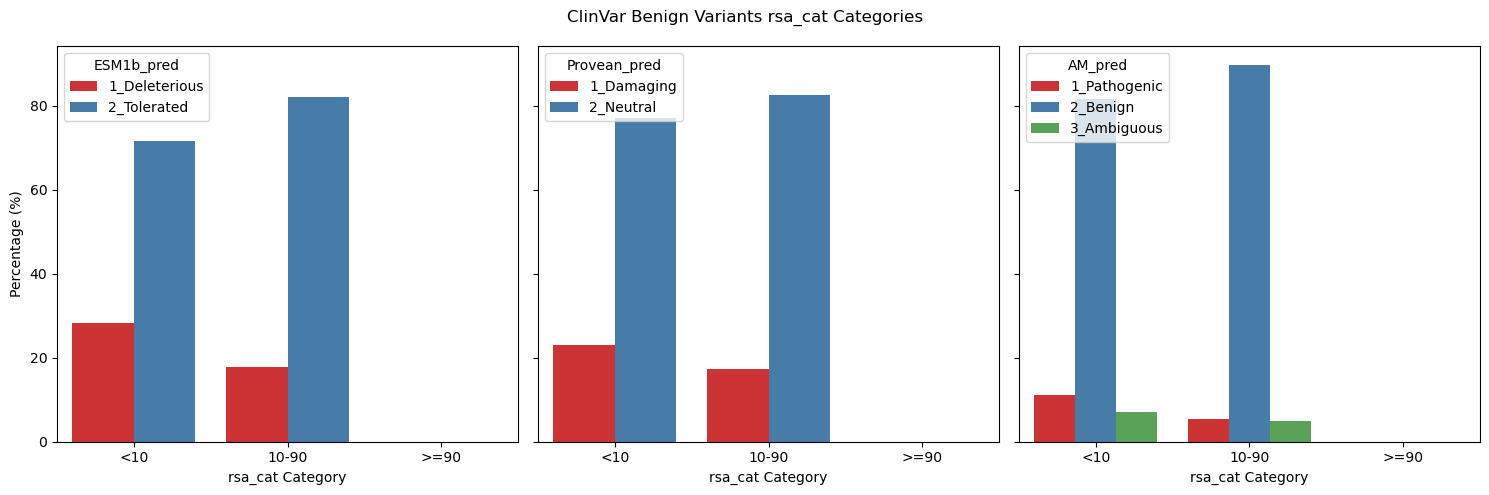

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", ">=90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="2_Benign")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Benign Variants {cat} Categories")
    plt.tight_layout()
    plt.show()